# Control de integridad del listado de sanciones OFAC

## Resumen
En el corte hay 19.564 filas y ningún identificador duplicado; la gráfica muestra los campos ausentes.

Una primera revisión de calidad identifica campos que necesitan tratamiento antes de comparar un listado con registros internos.

**Alcance:** -0- es un marcador de ausencia de la fuente. El chequeo mide completitud en un corte, no precisión de identidad, cobertura, eficacia del control ni cumplimiento legal; no se utilizan datos de clientes ni se ejecuta screening.

**Hallazgo del corte:** En este corte, 10.111 de 19.564 registros tienen el campo tipo vacío o `-0-` (51,68 %); esto requiere examinar el esquema y no demuestra un error de la fuente.

## Contexto y método
Aplicación descriptiva reproducible. Las cantidades son agregadas a partir del archivo citado; no se infiere causalidad ni desempeño institucional.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').exists())
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Datos
Corte de [OFAC SDN, formatos y esquema](https://ofac.treasury.gov/specially-designated-nationals-list-data-formats-data-schemas), descargado el 12 de noviembre de 2026; `-0-` representa un valor ausente. La unidad es una designación del archivo SDN; una ausencia puede ser legítima según el campo y el tipo de registro. Python con pandas, matplotlib y Jupyter; ejecutar desde la raíz o una subcarpeta del repositorio.

In [2]:
source = '03-financial-risk/05-enterprise-risk-advisory/05-financial-crime/aml-typologies/data/ofac_sdn_2026-11-12.csv'
p = root / source
print('Archivo:', source, '\nSHA-256:', hashlib.sha256(p.read_bytes()).hexdigest())
assert hashlib.sha256(p.read_bytes()).hexdigest() == '7f43332dae0d1b78ce44c31692d87a3c66e4075bcd97e36d3f18585572ff55b8', 'La instantánea cambió: revisar fecha, esquema y actualizar hash documentado'

Archivo: 03-financial-risk/05-enterprise-risk-advisory/05-financial-crime/aml-typologies/data/ofac_sdn_2026-11-12.csv 
SHA-256: 7f43332dae0d1b78ce44c31692d87a3c66e4075bcd97e36d3f18585572ff55b8


## Resultados

Duplicados de identificador: 0 | total de filas: 19564


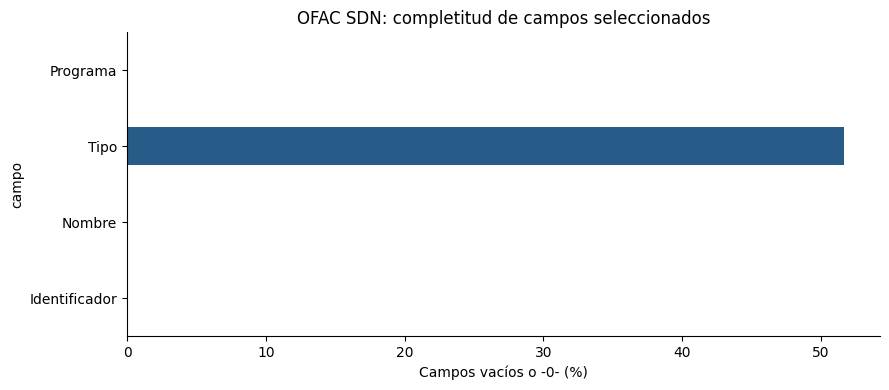

,campo,faltantes,filas,porcentaje
0,Identificador,0,19564,0.000000
1,Nombre,1,19564,0.005111
2,Tipo,10111,19564,51.681660
3,Programa,1,19564,0.005111


In [3]:
raw = pd.read_csv(root / source, header=None, dtype=str, keep_default_na=False)
assert raw.shape[1] == 12 and len(raw) > 0 and raw[0].str.strip().ne('').all()
fields = {0:'Identificador', 1:'Nombre', 2:'Tipo', 3:'Programa'}
quality = pd.DataFrame([{'campo':label, 'faltantes':int(raw[col].str.strip().isin(['','-0-']).sum()), 'filas':len(raw)} for col,label in fields.items()])
quality['porcentaje'] = quality.faltantes / quality.filas * 100
print('Duplicados de identificador:', raw[0].duplicated().sum(), '| total de filas:', len(raw))
assert raw[0].is_unique, 'La llave de designación no es única'
quality.set_index('campo').porcentaje.plot.barh(color='#285c88', xlabel='Campos vacíos o -0- (%)', title='OFAC SDN: completitud de campos seleccionados')
plt.tight_layout(); plt.show()
quality

## Variante: patrones conjuntos de información

El conteo por columna se complementa con patrones conjuntos entre nombre, tipo y programa. Cada patrón se interpreta únicamente como presencia o ausencia informada (`-0-` o vacío), no como error ni como tipo jurídico. El [marco de OFAC](https://ofac.treasury.gov/system/files/126/framework_ofac_cc.pdf) recomienda controles, pruebas y auditoría proporcionales al riesgo; detectar un campo ausente no evalúa si el sistema hace una búsqueda correcta. La [guía OFAC sobre falsos positivos](https://ofac.treasury.gov/media/16166/download?inline=) requiere revisión de coincidencias, información que este corte no contiene.

In [4]:
flags = pd.DataFrame({label:raw[col].str.strip().isin(['','-0-']) for col,label in {1:'nombre',2:'tipo',3:'programa'}.items()})
patterns = flags.value_counts(dropna=False).rename('designaciones').reset_index()
patterns['porcentaje'] = 100 * patterns.designaciones / len(raw)
assert patterns.designaciones.sum() == len(raw)
print('Denominador: designaciones del corte; True indica campo ausente o -0-.')
patterns.sort_values('designaciones', ascending=False).round(2)

Denominador: designaciones del corte; True indica campo ausente o -0-.


,nombre,tipo,programa,designaciones,porcentaje
0,False,True,False,10110,51.68
1,False,False,False,9453,48.32
2,True,True,True,1,0.01


## Interpretación y límites
-0- es un marcador de ausencia de la fuente. El chequeo mide completitud en un corte, no precisión de identidad, cobertura, eficacia del control ni cumplimiento legal; no se utilizan datos de clientes ni se ejecuta screening.

La cifra y la gráfica son descriptivas del corte disponible; las decisiones requieren datos propios, revisión de calidad y validación independiente.

**Acción siguiente:** contrastar con datos autorizados de la entidad, definir población y umbrales antes de cualquier decisión, y conservar la fecha y el hash del corte usado. Los controles de este notebook son de calidad local y no sustituyen revisión independiente.